# Ladle life prediction: time-series model development

**Goal:** estimate the current life (heats since the last reline) of each steel ladle from the shop-floor heat log, and serve it through an API.

Date, shift and heat number are used only to put each ladle's heats in order. The model sees the five process readings and features built from *earlier* heats in the same campaign, so no information leaks from the future.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / 'src'))
from pipeline.clean import PROCESS_COLUMNS, load_and_clean
from pipeline.features import FEATURE_COLUMNS, create_training_features
from pipeline.train import train_and_save

# Chart styling: validated categorical slots, recessive axes, text in neutral ink.
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.titlelocation': 'left',
    'font.size': 11, 'lines.linewidth': 2, 'figure.dpi': 110})
pd.set_option('display.precision', 3)

## 1. Data quality
The raw log has plant-style entries (`28+2`, `1550+4M`, `--`) and gaps. Each heat is kept even when a reading is missing: missing or out-of-range readings are filled with that ladle's median. **Dropping heats would break the heat count that ladle life is built on.** The first version of this pipeline dropped about 20% of heats, and that was the main reason its accuracy was poor.

In [2]:
raw_path = ROOT / 'data' / 'raw' / 'ladle_data_synthetic.xlsx'
raw = pd.read_excel(raw_path)
cleaned = load_and_clean(raw_path)
summary = pd.DataFrame({'raw rows': [len(raw)], 'heats kept': [len(cleaned)],
                        'heats with recorded life': [int(cleaned['ladle_life'].notna().sum())],
                        'ladles': [cleaned['ladle_no'].nunique()],
                        'date range': [f"{cleaned['date'].min():%d %b %Y} to {cleaned['date'].max():%d %b %Y}"]})
display(summary)
missing = raw.drop(columns=['Date', 'Shift', 'Heat No', 'Ldl No', 'P/Plug']).isna().mean().mul(100).round(1)
missing.rename('% missing in raw log').to_frame()

,raw rows,heats kept,heats with recorded life,ladles,date range
0,1656,1656,1590,8,01 Jun 2025 to 30 Jun 2025


,% missing in raw log
Ladle Life,4.0
Opening Temp.,7.7
Purging Time (Mins),11.1
LF Arcing Time (Mins),9.8
Treatment Time (Mins),7.9
Despatch Temp.,8.2


## 2. Campaigns and cycle-aware features
A **campaign** is the run of heats between two relines; a large drop in recorded life marks a reline. Ladles that were already in service when logging began start part-way through a campaign; their starting life is known at onboarding (the API takes it as `starting_life`).

For each heat, features use only *earlier* heats of the same campaign: heat count, cumulative and lagged process times, and 3- and 5-heat rolling means.

In [3]:
featured = create_training_features(cleaned)
campaigns = (featured.groupby(['ladle_no', 'campaign_id'])
             .agg(start=('date', 'min'), end=('date', 'max'), heats=('campaign_heats_observed', 'max'),
                  start_life=('expected_life', 'min'), last_life=('ladle_life', 'max'))
             .reset_index())
print(f'{len(FEATURE_COLUMNS)} model features, {len(campaigns)} campaigns')
campaigns

27 model features, 16 campaigns


,ladle_no,campaign_id,start,end,heats,start_life,last_life
0,8,1,2025-06-01,2025-06-13,85,1.0,85.0
1,8,2,2025-06-14,2025-06-30,121,1.0,121.0
2,16,1,2025-06-01,2025-06-07,52,1.0,52.0
3,16,2,2025-06-08,2025-06-30,157,1.0,157.0
4,18,1,2025-06-01,2025-06-07,46,1.0,46.0
5,18,2,2025-06-08,2025-06-30,154,1.0,154.0
6,20,1,2025-06-01,2025-06-08,62,1.0,62.0
7,20,2,2025-06-09,2025-06-30,155,1.0,155.0
8,21,1,2025-06-01,2025-06-09,60,1.0,60.0
9,21,2,2025-06-09,2025-06-30,149,1.0,149.0


## 3. Model training and selection
**Model design.** Life keeps rising within a campaign, so a tree model trained directly on life cannot predict above the highest life it saw in training. The production model therefore predicts life as **the campaign heat counter plus a learned correction**.

**Validation.** Walk-forward: train on everything before a cutoff date and test on everything after it, at three cutoffs (60%, 70%, 80% of dates). There is no random shuffling. The 80% cutoff is the reported holdout.

**Candidates.** The heat counter alone (reference), the original direct ExtraTrees model, and the counter + correction with Ridge, XGBoost or ExtraTrees. The candidate with the lowest mean walk-forward MAE is refit on all data and saved.

In [4]:
metadata = train_and_save(raw_path)
labels = {'heat_counter_baseline': 'Heat counter only (reference)', 'direct_extra_trees': 'Direct ExtraTrees (original approach)',
          'residual_ridge': 'Counter + Ridge correction', 'residual_xgboost': 'Counter + XGBoost correction',
          'residual_extra_trees': 'Counter + ExtraTrees correction'}
results = pd.DataFrame({labels[name]: {'walk-forward MAE (heats)': m['cv_mean']['mae'], 'walk-forward R²': m['cv_mean']['r2'],
                                       'holdout MAE (heats)': m['holdout']['mae'], 'holdout R²': m['holdout']['r2']}
                        for name, m in metadata['metrics'].items()}).T
print(f"Selected model: {labels[metadata['model_name']]}  |  holdout from {metadata['time_split_cutoff'][:10]}, "
      f"{metadata['test_rows']} heats")
results.style.format('{:.3f}')

Selected model: Counter + ExtraTrees correction  |  holdout from 2025-06-25, 324 heats


,walk-forward MAE (heats),walk-forward R²,holdout MAE (heats),holdout R²
Heat counter only (reference),0.044,1.000,0.046,1.000
Direct ExtraTrees (original approach),23.818,-0.983,16.614,-0.645
Counter + Ridge correction,0.068,1.000,0.064,1.000
Counter + XGBoost correction,0.081,1.000,0.082,1.000
Counter + ExtraTrees correction,0.059,1.000,0.061,1.000


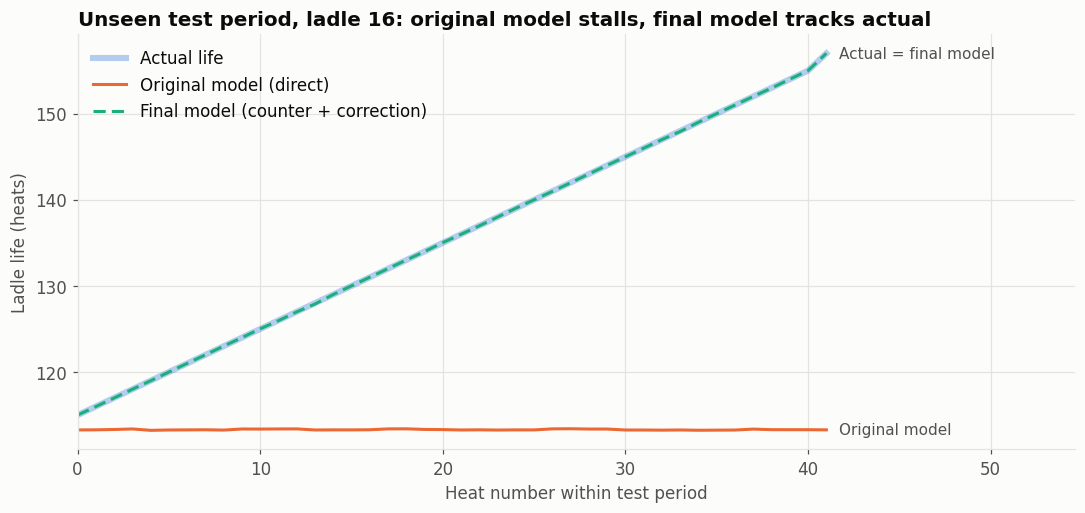

In [5]:
holdout = pd.read_csv(ROOT / 'data' / 'processed' / 'holdout_predictions.csv', parse_dates=['date'])
ladle = holdout.groupby('ladle_no')['ladle_life'].max().idxmax()
one = holdout[holdout['ladle_no'] == ladle].reset_index(drop=True)
chosen = f"pred_{metadata['model_name']}"

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(one.index, one['ladle_life'], color=BLUE, linewidth=4, alpha=0.35, label='Actual life')
ax.plot(one.index, one['pred_direct_extra_trees'], color=ORANGE, label='Original model (direct)')
ax.plot(one.index, one[chosen], color=AQUA, linestyle=(0, (4, 2)), label='Final model (counter + correction)')
for column, text in [('ladle_life', 'Actual = final model'), ('pred_direct_extra_trees', 'Original model')]:
    ax.annotate(text, (one.index[-1], one[column].iloc[-1]), xytext=(8, 0), textcoords='offset points',
                va='center', color=MUTED, fontsize=10)
ax.set_title(f'Unseen test period, ladle {ladle}: original model stalls, final model tracks actual')
ax.set_xlabel('Heat number within test period'); ax.set_ylabel('Ladle life (heats)')
ax.set_xlim(0, len(one) * 1.3); ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

**Reading the results**

* The original direct model stops near the highest life it saw in training, so its error grows as the campaign continues (negative R²).
* Keeping every heat and building the model on the heat counter gives near-exact tracking of ladle life on unseen dates.
* On this dataset the heat counter alone is already about as accurate as the learned correction: ladle life here is driven almost entirely by heat count. The learned correction is kept because real plant logs have missed or duplicated heats, which a pure counter cannot detect, and the walk-forward check shows the correction adds no meaningful error.

## 4. Wear signal in the process readings
Treatment and arcing times lengthen and temperatures fall as the refractory lining wears. This is a real wear signal that a future remaining-life model can use.

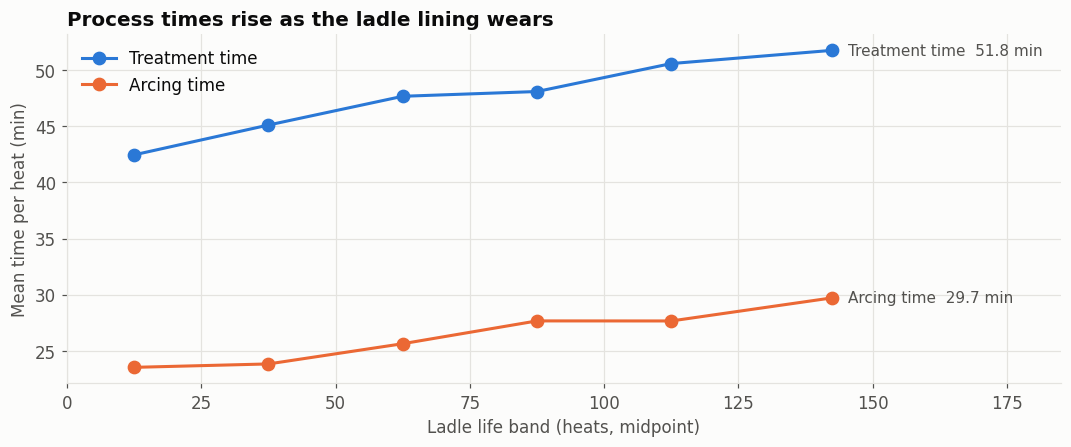

,treatment_time,arcing_time
life_band,,
"(0, 25]",42.5,23.5
"(25, 50]",45.1,23.8
"(50, 75]",47.7,25.6
"(75, 100]",48.1,27.7
"(100, 125]",50.6,27.7
"(125, 160]",51.8,29.7


In [6]:
bins = [0, 25, 50, 75, 100, 125, 160]
trend = (featured.dropna(subset=['ladle_life'])
         .assign(life_band=lambda f: pd.cut(f['ladle_life'], bins))
         .groupby('life_band', observed=True)[['treatment_time', 'arcing_time']].mean())
mid = [(b.left + b.right) / 2 for b in trend.index]

fig, ax = plt.subplots(figsize=(10, 4.2))
for column, text, color in [('treatment_time', 'Treatment time', BLUE), ('arcing_time', 'Arcing time', ORANGE)]:
    ax.plot(mid, trend[column], color=color, marker='o', markersize=8, label=text)
    ax.annotate(f'{text}  {trend[column].iloc[-1]:.1f} min', (mid[-1], trend[column].iloc[-1]), xytext=(10, 0),
                textcoords='offset points', va='center', color=MUTED, fontsize=10)
ax.set_title('Process times rise as the ladle lining wears')
ax.set_xlabel('Ladle life band (heats, midpoint)'); ax.set_ylabel('Mean time per heat (min)')
ax.set_xlim(0, 185); ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()
trend.round(1)

## 5. Summary and next steps
* **Data pipeline:** robust parsing of plant-style values; no heats dropped; campaigns and relines detected automatically.
* **Model:** heat counter plus a learned correction, chosen by walk-forward validation. It is accurate on unseen dates and cannot stall on long campaigns.
* **Serving:** the FastAPI service rebuilds the same features from stored heat history, so training and live features match (this is covered by a unit test).
* **Next:** predict **remaining life** (heats until reline) from the wear signal above once more complete campaigns are logged. This dataset has only 8 completed campaigns, too few for a reliable model.

Saved outputs: `data/processed/ladle_features.csv`, `data/processed/holdout_predictions.csv`, `src/models/ladle_life_pipeline.pkl`, `src/models/model_metadata.json`.